In [1]:
from google.colab import auth
auth.authenticate_user()

In [2]:
!gsutil ls gs://sen1floods11/

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
gs://sen1floods11/v1.1/


In [3]:
!gcloud storage ls gs://sen1floods11/v1.1/
!gcloud storage ls gs://sen1floods11/v1.1/data/flood_events/HandLabeled/
!gcloud storage ls gs://sen1floods11/v1.1/splits/

gs://sen1floods11/v1.1/Sen1Floods11_Metadata.geojson
gs://sen1floods11/v1.1/catalog.zip
gs://sen1floods11/v1.1/catalog/
gs://sen1floods11/v1.1/checkpoints/
gs://sen1floods11/v1.1/data/
gs://sen1floods11/v1.1/splits/
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/JRCWaterHand/
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1OtsuLabelHand/
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S2Hand/
gs://sen1floods11/v1.1/splits/flood_handlabeled/
gs://sen1floods11/v1.1/splits/perm_water/


In [7]:
# S1Hand(입력) / LabelHand(정답) / splits/flood_handlabeled(분할목록) 데이터 활용
!mkdir -p /content/data/{S1Hand,LabelHand,splits}
B = "gs://sen1floods11/v1.1"
!gcloud storage rsync -r $B/data/flood_events/HandLabeled/S1Hand    /content/data/S1Hand
!gcloud storage rsync -r $B/data/flood_events/HandLabeled/LabelHand /content/data/LabelHand
!gcloud storage rsync -r $B/splits/flood_handlabeled                /content/data/splits

At gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/**, worker process 11023 thread 136737208131712 listed 446...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_103757_S1Hand.tif to file:///content/data/S1Hand/Bolivia_103757_S1Hand.tif
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_129334_S1Hand.tif to file:///content/data/S1Hand/Bolivia_129334_S1Hand.tif
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_195474_S1Hand.tif to file:///content/data/S1Hand/Bolivia_195474_S1Hand.tif
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_23014_S1Hand.tif to file:///content/data/S1Hand/Bolivia_23014_S1Hand.tif
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_233925_S1Hand.tif to file:///content/data/S1Hand/Bolivia_233925_S1Hand.tif
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_242570_S1Hand.tif to file:///content/data/S1Ha

In [8]:
# S1Hand, LabelHand 446개 데이터 처리
# 이벤트 11개 (Bolivia, Ghana, India, Mekong, Nigeria, Pakistan, Paraguay, Somalia, Spain, Sri-Lanka, USA)
#분할 파일은 flood_train_data.csv, flood_valid_data.csv, flood_test_data.csv, flood_bolivia_data.csv

In [9]:
#분할 파일(CSV)의 형식 확인
import pandas as pd, glob, os
for f in sorted(glob.glob("/content/data/splits/*.csv")):
  df = pd.read_csv(f, header=None)
  print(os.path.basename(f), df.shape)
  print(df.head(2).to_string())

flood_bolivia_data.csv (15, 2)
                           0                             1
0  Bolivia_103757_S1Hand.tif  Bolivia_103757_LabelHand.tif
1  Bolivia_129334_S1Hand.tif  Bolivia_129334_LabelHand.tif
flood_test_data.csv (90, 2)
                          0                            1
0   Ghana_313799_S1Hand.tif   Ghana_313799_LabelHand.tif
1  Ghana_1078550_S1Hand.tif  Ghana_1078550_LabelHand.tif
flood_train_data.csv (252, 2)
                         0                           1
0  Ghana_103272_S1Hand.tif  Ghana_103272_LabelHand.tif
1   Ghana_24858_S1Hand.tif   Ghana_24858_LabelHand.tif
flood_valid_data.csv (89, 2)
                         0                           1
0    Ghana_5079_S1Hand.tif    Ghana_5079_LabelHand.tif
1  Ghana_895194_S1Hand.tif  Ghana_895194_LabelHand.tif


In [10]:
#확인 결과 분할파일 4개 모두 열 2개(첫열은 S1파일명, 둘째 열은 라벨 파일명)
#<행 개수>
#train_data 252, valid 89, test 90, bolivia 15 >총 446

In [11]:
#GeoTiff 데이터 읽는 도구
!pip -q install segmentation-models-pytorch rasterio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.0 MB/s eta 0:00:00


In [16]:
import numpy as np, pandas as pd, rasterio, torch, random
from collections import Counter
from torch.utils.data import Dataset

ROOT = "/content/data"

def read_split(name):
  df = pd.read_csv(f"{ROOT}/splits/{name}", header=None)
  return df[0].tolist(), df[1].tolist()

class Flood(Dataset):
  def __init__(self, csv_name):
    self.s1, self.lb = read_split(csv_name)
  def __len__(self):
    return len(self.s1)
  def __getitem__(self, i):
    with rasterio.open(f"{ROOT}/S1Hand/{self.s1[i]}") as f:
      x = f.read().astype(np.float32) # (2, 512, 512) VV, VH
    with rasterio.open(f"{ROOT}/LabelHand/{self.lb[i]}") as f:
      y = f.read(1).astype(np.int64)   # -1, 0, 1
    return torch.from_numpy(x), torch.from_numpy(y)

#1) 분할별 이벤트 분포 (test에 여러 이벤트 섞여 있는지 확인)
for name in ["train", "valid", "test", "bolivia"]:
  s1, _ = read_split(f"flood_{name}_data.csv")
  print(name, dict(Counter(s.split("_")[0] for s in s1)))

#2) 샘플 한 장의 값 범위 (입력 갑의 범위 및 NaN 여부 / 라벨값이 -1,0,1 중 무엇인지)
x, y = Flood("flood_train_data.csv")[0]
print("x", x.shape, x.dtype, "min/max", float(np.nanmin(x)), float(np.nanmax(x)),
      "Nan개수", int(torch.isnan(x).sum()))
print("y", y.shape, "라벨값", y.unique().tolist())

train {'Ghana': 31, 'India': 40, 'Mekong': 18, 'Nigeria': 10, 'Pakistan': 16, 'Paraguay': 39, 'Somalia': 15, 'Spain': 18, 'Sri-Lanka': 24, 'USA': 41}
valid {'Ghana': 11, 'India': 14, 'Mekong': 6, 'Nigeria': 4, 'Pakistan': 6, 'Paraguay': 14, 'Somalia': 5, 'Spain': 6, 'Sri-Lanka': 9, 'USA': 14}
test {'Ghana': 11, 'India': 14, 'Mekong': 6, 'Nigeria': 4, 'Pakistan': 6, 'Paraguay': 14, 'Somalia': 6, 'Spain': 6, 'Sri-Lanka': 9, 'USA': 14}
bolivia {'Bolivia': 15}
x torch.Size([2, 512, 512]) torch.float32 min/max -47.37702941894531 8.586925506591797 Nan개수 0
y torch.Size([512, 512]) 라벨값 [-1, 0, 1]


In [19]:
#정규화 및 클래스 비율 설정
#이를 위해 train 전체의 통계 필요

from collections import Counter

def scan(csv_name, full=False):
  ds = Flood(csv_name)
  nan_chips = 0
  s = np.zeros(2); s2 = np.zeros(2); cnt = np.zeros(2)
  mn = np. full(2, np.inf); mx = np.full(2, -np.inf)
  lab = Counter()
  for i in range(len(ds)):
    x, y = ds[i]
    x = x.numpy().astype(np.float64)
    if np.isnan(x).any():
      nan_chips += 1
    if full:
      for c  in range(2):
        v = x[c][~np.isnan(x[c])]
        s[c] += v.sum(); s2[c] += (v**2).sum(); cnt[c] += v.size
        mn[c] = min(mn[c], v.min()); mx[c] = max(mx[c], v.max())
      u, k = np.unique(y.numpy(), return_counts=True)
      lab.update(dict(zip(u.tolist(), k.tolist())))
  print(csv_name, "| Nan 있는 칩:", nan_chips, "/", len(ds))
  if full:
    mean = s / cnt
    std = np.sqrt(s2 / cnt - mean**2)
    print("채널 [VV, VH] mean:", mean.round(2), "std:", std.round(2))
    print("채널 [VV, VH] min:", mn.round(1), "max:", mx.round(1))
    tot = sum(lab.values())
    print("라벨 비율:", {k: round(v / tot, 4) for k, v in sorted(lab.items())})
    valid = lab[0] + lab[1]
    print("유효 픽셀 중 물 비율:", round(lab[1] / valid, 4))

scan("flood_train_data.csv", full=True)
for n in ["valid", "test", "bolivia"]:
  scan(f"flood_{n}_data.csv")

flood_train_data.csv | Nan 있는 칩: 23 / 252
채널 [VV, VH] mean: [-10.39 -17.24] std: [4.04 4.75]
채널 [VV, VH] min: [-65.5 -79.2] max: [29.9 17.4]
라벨 비율: {-1: 0.1326, 0: 0.785, 1: 0.0825}
유료 픽셀 중 물 비율: 0.0951
flood_valid_data.csv | Nan 있는 칩: 9 / 89
flood_test_data.csv | Nan 있는 칩: 6 / 90
flood_bolivia_data.csv | Nan 있는 칩: 8 / 15


In [20]:
#-1 -> No data 비율은 13.3%, 이는 training 및 test에서 제외
#물 픽셀은 유효 픽셀의 9.5% 뿐 -> accuracy score 대신 IoU 및 F1 사용
#VV, VH 채널에 극단값 존재, 해당 값들은 제거해야 함

In [27]:
#정규화, 데이터로더, 모델 만들기
import segmentation_models_pytorch as smp
from torch.utils.data import DataLoader

MEAN = np.array([-10.39, -17.24], dtype=np.float32). reshape(2, 1, 1)
STD = np.array([4.04, 4.75], dtype=np.float32).reshape(2, 1, 1)

class FloodN(Flood):
  def __init__(self, csv_name, train=False, crop=256):
    super().__init__(csv_name)
    self.train, self.crop = train, crop
  def __getitem__(self, i):
    x, y = super().__getitem__(i)
    x, y = x.numpy(), y.numpy()
    x = np.clip(x, MEAN - 5 * STD, MEAN + 5 * STD)
    x = (x - MEAN) / STD
    x = np.nan_to_num(x, nan=0.0)
    if self.train:
      c = self.crop
      t = random.randint(0, y.shape[0] - c)
      l = random.randint(0, y.shape[1] - c)
      x, y = x[:, t:t+c, l:l+c], y[t:t+c, l:l+c]
      if random.random() < 0.5: x, y = x[:, :, ::-1], y[:, ::-1]
      if random.random() < 0.5: x, y = x[:, ::-1, :], y[::-1, :]
    return (torch.from_numpy(np.ascontiguousarray(x)),
            torch.from_numpy(np.ascontiguousarray(y)))

train_d1 = DataLoader(FloodN("flood_train_data.csv", train=True), batch_size=8,
                      shuffle=True, num_workers=2)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = smp.Unet(encoder_name="resnet34", encoder_weights=None,
                  in_channels=2, classes=2).to(device)

xb, yb = next(iter(train_d1))
with torch.no_grad():
  out = model(xb.to(device))
print("device:", device)
print("입력", xb.shape, "| 라벨", yb.shape, "| 출력", out.shape)
print("입력 mean/std:", float(xb.mean()), float(xb.std()), "| NaN:", bool(torch.isnan(xb).any()))

device: cuda
입력 torch.Size([8, 2, 256, 256]) | 라벨 torch.Size([8, 256, 256]) | 출력 torch.Size([8, 2, 256, 256])
입력 mean/std: -0.34432995319366455 1.4492924213409424 | NaN: False


In [ ]:
#device cuda 확인, 입력과 라벨, 출력의 모양 모두 예상과 같으며, NaN 없음을 확인

In [33]:
#loss, 학습 루프, 평가
#IoU: 모델이 물이라고 한 영역과 실제 물 영역의 교집합을 합집합으로 나눔
#F1:  정밀도(물이라고 한 것 중 맞은 비율)와 재현율(실제 물 중 찾아낸 비율)의 조화평균
#-1라벨 픽셀은 loss 및 평가에서 모두 제외, 평가는 칩별 평균이 아닌 뷴할 전체의 픽셀을 합산해서 계산
import torch.nn.functional as F, time, os
CKPT = "/content/ckpt"; os.makedirs(CKPT, exist_ok=True)
CW = torch.tensor([1.0, 3.0]).to(device)  #물 클래스 가중치(출발점 추정치)

class Sel(torch.utils.data.Dataset):
  def __init__(self, ds, chans): self.ds, self.chans = ds, list(chans)
  def __len__(self): return len(self.ds)
  def __getitem__(self, i):
    x, y = self.ds[i]
    return x[self.chans], y

def loss_fn(out, y):
  ce = F.cross_entropy(out, y, weight=CW, ignore_index=-1)
  p = out.softmax(1)[:, 1]
  m = (y != -1).float(); t = (y == 1).float()
  inter = (p * t * m).sum()
  dice = 1 - (2 * inter + 1) / ((p * m).sum() + (t * m).sum() + 1)
  return ce + dice

@torch.no_grad()
def evaluate(model, dl):
  model.eval(); tp = fp = fn = 0
  for x, y, in dl:
    x, y = x.to(device), y.to(device)
    pred = model(x).argmax(1)
    tp += int(((pred == 1) & (y == 1)).sum())
    fp += int(((pred == 1) & (y == 0)).sum())
    fn += int(((pred == 0) & (y == 1)).sum())
  P = tp / max(tp + fp, 1); R = tp / max(tp + fn, 1)
  return dict(IoU=tp / max(tp + fp + fn, 1), F1=2 * P * R / max(P + R, 1e-9),
              P=P, R=R)

def run(chans=(0, 1), epochs=50, lr=1e-3, tag="unet_vvvh", seed=0):
  torch.manual_seed(seed); random.seed(seed); np.random.seed(seed)
  tr = DataLoader(Sel(FloodN("flood_train_data.csv", train=True), chans),
                  batch_size=8, shuffle=True, num_workers=2)
  mk = lambda n : DataLoader(Sel(FloodN(f"flood_{n}_data.csv"), chans),
                            batch_size=4, num_workers=2)
  va, te, bo = mk("valid"), mk("test"), mk("bolivia")
  model = smp.Unet("resnet34", encoder_weights=None,
                   in_channels=len(chans), classes=2).to(device)
  opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
  sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
  best, t0 = -1, time.time()
  for ep in range(1, epochs + 1):
    model.train(); tot = 0
    for x, y in tr:
      x, y = x.to(device), y.to(device)
      loss = loss_fn(model(x), y)
      opt.zero_grad(); loss.backward(); opt.step()
      tot += loss.item()
    sch.step()
    v = evaluate(model, va)
    if v["IoU"] > best:
      best = v["IoU"]; torch.save(model.state_dict(), f"{CKPT}/{tag}.pt")
    if ep%5 == 0 or ep == 1:
      print(f"ep{ep:02d} loss {tot/len(tr):.3f} | valid IoU {v['IoU']:.3f} "
            f"F1 {v['F1']:.3f} | best {best:.3f} | {time.time()-t0:.0f}s")
  model.load_state_dict(torch.load(f"{CKPT}/{tag}.pt"))
  for n, dl in [("valid", va), ("test", te), ("bolivia", bo)]:
    r = evaluate(model, dl)
    print(f"[{tag}] {n:8s}", {k: round(val, 3) for k, val in r.items()})
  return model

In [34]:
#모델 점검용
m = run(epochs=2, tag="smoke")

ep01 loss 1.025 | valid IoU 0.490F1 0.658 | best 0.490 | 12s
[smoke] valid    {'IoU': 0.612, 'F1': 0.759, 'P': 0.767, 'R': 0.752}
[smoke] test     {'IoU': 0.618, 'F1': 0.764, 'P': 0.758, 'R': 0.769}
[smoke] bolivia  {'IoU': 0.608, 'F1': 0.756, 'P': 0.854, 'R': 0.679}


In [35]:
#50 epoch 전체 학습
RESULTS = []
def report(model, chans, tag):
  mk = lambda n: DataLoader(Sel(FloodN(f"flood_{n}_data.csv"), chans),
                            batch_size=4, num_workers=2)
  for n in ["valid", "test", "bolivia"]:
    r = evaluate(model, mk(n))
    RESULTS.append(dict(model=tag, split=n, **{k: round(v, 3) for k, v in r.items()}))

In [36]:
m_full = run(chans=(0, 1), epochs=50, tag="unet_vvvh")
report(m_full, (0, 1), "VV+VH")
import pandas as pd
print(pd.DataFrame(RESULTS).to_string(index=False))

ep01 loss 1.024 | valid IoU 0.113F1 0.204 | best 0.113 | 11s
ep05 loss 0.833 | valid IoU 0.589F1 0.741 | best 0.602 | 54s
ep10 loss 0.809 | valid IoU 0.578F1 0.733 | best 0.603 | 109s
ep15 loss 0.830 | valid IoU 0.548F1 0.708 | best 0.607 | 163s
ep20 loss 0.729 | valid IoU 0.614F1 0.761 | best 0.614 | 216s
ep25 loss 0.733 | valid IoU 0.618F1 0.764 | best 0.623 | 269s
ep30 loss 0.712 | valid IoU 0.622F1 0.767 | best 0.626 | 322s
ep35 loss 0.711 | valid IoU 0.627F1 0.770 | best 0.627 | 374s
ep40 loss 0.689 | valid IoU 0.629F1 0.772 | best 0.640 | 427s
ep45 loss 0.631 | valid IoU 0.633F1 0.775 | best 0.640 | 480s
ep50 loss 0.688 | valid IoU 0.637F1 0.778 | best 0.645 | 533s
[unet_vvvh] valid    {'IoU': 0.645, 'F1': 0.784, 'P': 0.783, 'R': 0.786}
[unet_vvvh] test     {'IoU': 0.664, 'F1': 0.798, 'P': 0.787, 'R': 0.808}
[unet_vvvh] bolivia  {'IoU': 0.674, 'F1': 0.805, 'P': 0.835, 'R': 0.778}
model   split   IoU    F1     P     R
VV+VH   valid 0.645 0.784 0.783 0.786
VV+VH    test 0.664 0.798

In [37]:
#어느 편파가 홍수 탐지에 기여하는지 확인

In [38]:
#only VV (채널 0)
m_vv = run(chans=(0,), epochs=50, tag="unet_vv")
report(m_vv, (0,), "VV only")

ep01 loss 1.243 | valid IoU 0.386F1 0.557 | best 0.386 | 11s
ep05 loss 1.008 | valid IoU 0.548F1 0.708 | best 0.548 | 54s
ep10 loss 0.880 | valid IoU 0.568F1 0.725 | best 0.568 | 108s
ep15 loss 0.936 | valid IoU 0.543F1 0.704 | best 0.568 | 161s
ep20 loss 0.887 | valid IoU 0.522F1 0.686 | best 0.568 | 213s
ep25 loss 0.893 | valid IoU 0.571F1 0.727 | best 0.583 | 265s
ep30 loss 0.820 | valid IoU 0.577F1 0.732 | best 0.590 | 318s
ep35 loss 0.816 | valid IoU 0.585F1 0.738 | best 0.594 | 371s
ep40 loss 0.796 | valid IoU 0.580F1 0.734 | best 0.602 | 423s
ep45 loss 0.870 | valid IoU 0.586F1 0.739 | best 0.602 | 475s
ep50 loss 0.753 | valid IoU 0.596F1 0.747 | best 0.602 | 528s
[unet_vv] valid    {'IoU': 0.602, 'F1': 0.752, 'P': 0.794, 'R': 0.714}
[unet_vv] test     {'IoU': 0.563, 'F1': 0.72, 'P': 0.773, 'R': 0.674}
[unet_vv] bolivia  {'IoU': 0.681, 'F1': 0.81, 'P': 0.796, 'R': 0.825}


In [39]:
#only VH (채널1)
m_vh = run(chans=(1,), epochs=50, tag="unet_vh")
report(m_vh, (1,), "VH only")

ep01 loss 1.148 | valid IoU 0.250F1 0.400 | best 0.250 | 11s
ep05 loss 0.851 | valid IoU 0.526F1 0.689 | best 0.547 | 53s
ep10 loss 0.759 | valid IoU 0.599F1 0.749 | best 0.599 | 105s
ep15 loss 0.845 | valid IoU 0.591F1 0.743 | best 0.599 | 158s
ep20 loss 0.782 | valid IoU 0.582F1 0.735 | best 0.599 | 210s
ep25 loss 0.800 | valid IoU 0.569F1 0.725 | best 0.599 | 262s
ep30 loss 0.732 | valid IoU 0.597F1 0.747 | best 0.599 | 314s
ep35 loss 0.739 | valid IoU 0.602F1 0.752 | best 0.602 | 367s
ep40 loss 0.683 | valid IoU 0.584F1 0.737 | best 0.604 | 419s
ep45 loss 0.767 | valid IoU 0.598F1 0.748 | best 0.607 | 471s
ep50 loss 0.667 | valid IoU 0.602F1 0.751 | best 0.608 | 524s
[unet_vh] valid    {'IoU': 0.608, 'F1': 0.756, 'P': 0.771, 'R': 0.742}
[unet_vh] test     {'IoU': 0.634, 'F1': 0.776, 'P': 0.788, 'R': 0.764}
[unet_vh] bolivia  {'IoU': 0.687, 'F1': 0.814, 'P': 0.864, 'R': 0.77}


In [41]:
#VV + VH > seed1 (노이즈 확인용)
m_s1 = run(chans=(0, 1), epochs=50, tag="unet_vvvh_s1", seed=1)
report(m_s1, (0, 1), "VV+VH seed1")
print(pd.DataFrame(RESULTS).to_string(index=False))

ep01 loss 1.050 | valid IoU 0.227F1 0.371 | best 0.227 | 11s
ep05 loss 0.834 | valid IoU 0.593F1 0.745 | best 0.593 | 55s
ep10 loss 0.833 | valid IoU 0.547F1 0.707 | best 0.604 | 108s
ep15 loss 0.763 | valid IoU 0.600F1 0.750 | best 0.615 | 161s
ep20 loss 0.663 | valid IoU 0.621F1 0.766 | best 0.623 | 214s
ep25 loss 0.715 | valid IoU 0.625F1 0.769 | best 0.627 | 268s
ep30 loss 0.712 | valid IoU 0.611F1 0.759 | best 0.627 | 321s
ep35 loss 0.680 | valid IoU 0.619F1 0.765 | best 0.635 | 374s
ep40 loss 0.632 | valid IoU 0.623F1 0.768 | best 0.635 | 431s
ep45 loss 0.657 | valid IoU 0.626F1 0.770 | best 0.635 | 484s
ep50 loss 0.692 | valid IoU 0.622F1 0.767 | best 0.635 | 537s
[unet_vvvh_s1] valid    {'IoU': 0.635, 'F1': 0.777, 'P': 0.781, 'R': 0.773}
[unet_vvvh_s1] test     {'IoU': 0.655, 'F1': 0.792, 'P': 0.787, 'R': 0.796}
[unet_vvvh_s1] bolivia  {'IoU': 0.633, 'F1': 0.775, 'P': 0.848, 'R': 0.714}
      model   split   IoU    F1     P     R
      VV+VH   valid 0.645 0.784 0.783 0.786
    

In [44]:
#VV + VH > seed2 (노이즈 확인용)
m_s2 = run(chans=(0, 1), epochs=50, tag="unet_vvvh_s2", seed=2)
report(m_s2, (0, 1), "VV+VH seed2")

ep01 loss 1.073 | valid IoU 0.290F1 0.450 | best 0.290 | 11s
ep05 loss 0.859 | valid IoU 0.522F1 0.686 | best 0.608 | 57s
ep10 loss 0.800 | valid IoU 0.407F1 0.579 | best 0.608 | 112s
ep15 loss 0.830 | valid IoU 0.623F1 0.768 | best 0.623 | 166s
ep20 loss 0.780 | valid IoU 0.613F1 0.760 | best 0.623 | 220s
ep25 loss 0.708 | valid IoU 0.628F1 0.772 | best 0.628 | 276s
ep30 loss 0.708 | valid IoU 0.621F1 0.766 | best 0.630 | 330s
ep35 loss 0.699 | valid IoU 0.615F1 0.762 | best 0.630 | 383s
ep40 loss 0.707 | valid IoU 0.620F1 0.765 | best 0.630 | 437s
ep45 loss 0.666 | valid IoU 0.626F1 0.770 | best 0.630 | 490s
ep50 loss 0.662 | valid IoU 0.625F1 0.769 | best 0.630 | 544s
[unet_vvvh_s2] valid    {'IoU': 0.63, 'F1': 0.773, 'P': 0.807, 'R': 0.743}
[unet_vvvh_s2] test     {'IoU': 0.665, 'F1': 0.799, 'P': 0.814, 'R': 0.785}
[unet_vvvh_s2] bolivia  {'IoU': 0.627, 'F1': 0.771, 'P': 0.851, 'R': 0.704}


In [ ]:
import shutil, os

# 결과 저장 위치 (로컬). 필요하면 Drive 경로로 바꿔서 사용
OUT = "/content/out/sen1floods11_run"
os.makedirs(OUT, exist_ok=True)
shutil.copytree("/content/ckpt", f"{OUT}/ckpt", dirs_exist_ok=True)
pd.DataFrame(RESULTS).to_csv(f"{OUT}/results.csv", index=False)
print(os.listdir(OUT), os.listdir(f"{OUT}/ckpt"))


In [ ]:
#정리용 셀 -> 중복을 합치고 요약표를 생성
df = pd.DataFrame(RESULTS)
# 같은 모델을 재실행해 중복된 행은 마지막 실행만 사용 (rename 전에 처리)
df = df.drop_duplicates(subset=["model", "split"], keep="last")
df["model"] = df["model"].replace({"VV+VH seed1": "VV+VH", "VV+VH seed2": "VV+VH"})
df = df[df.split != "valid"]
summary = (df.groupby(["model", "split"])["IoU"]
             .agg(["mean", "min", "max", "count"]).round(3))
print(summary)
summary.to_csv(f"{OUT}/summary_iou.csv")

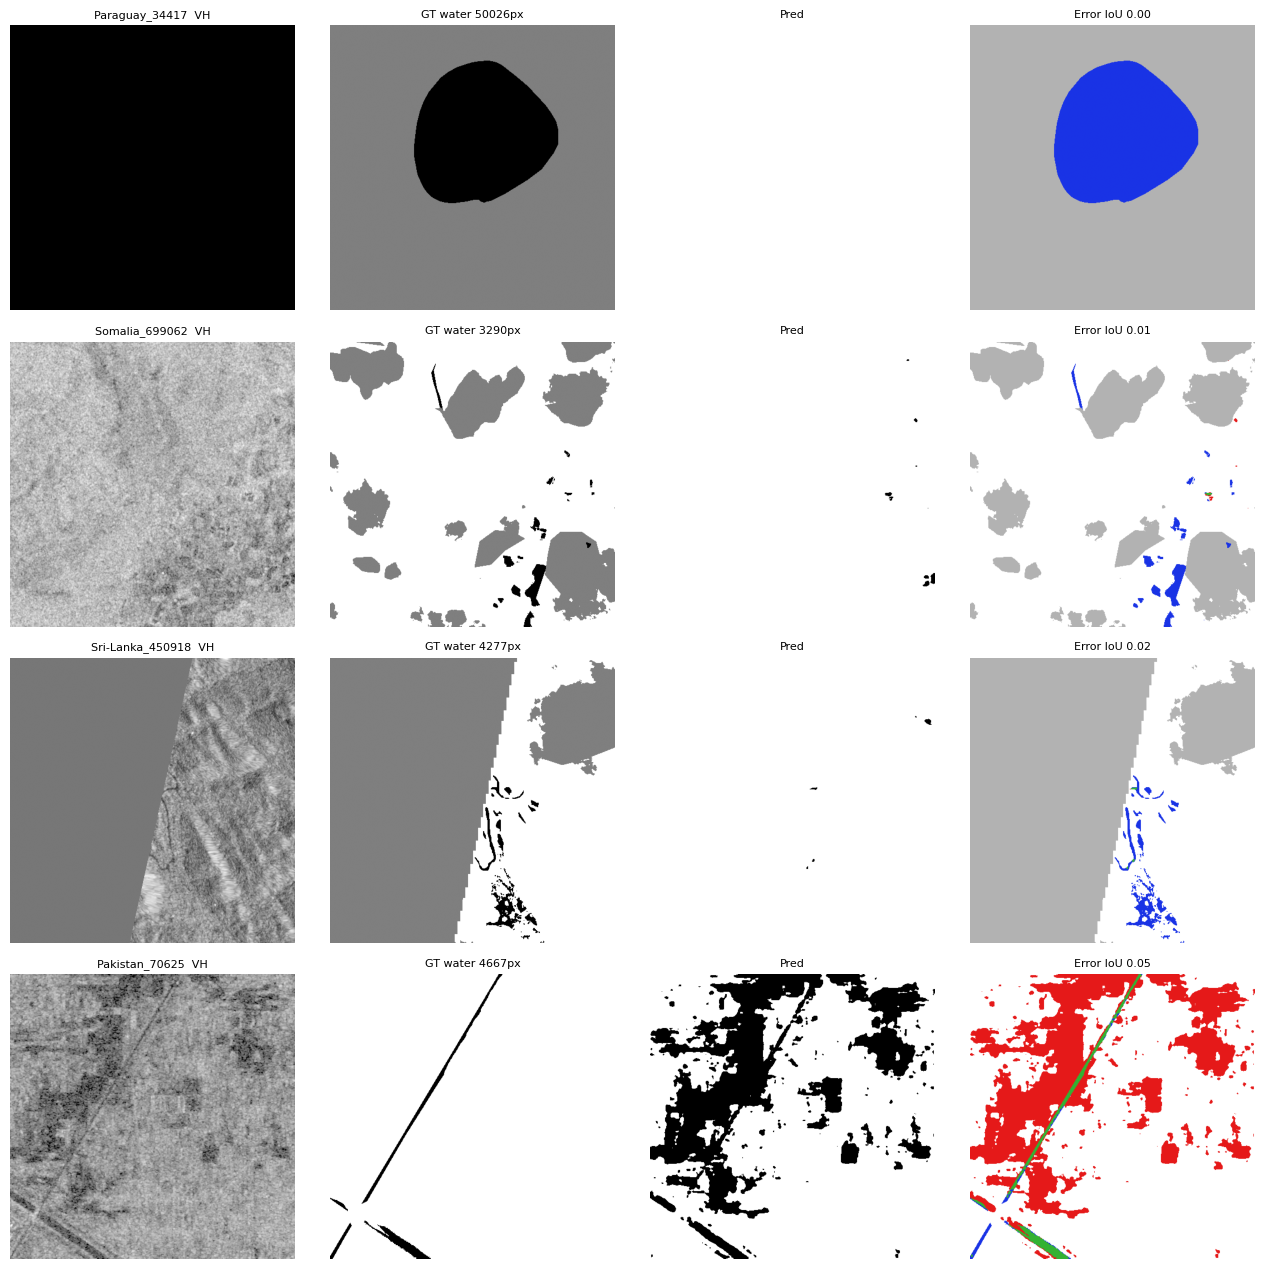

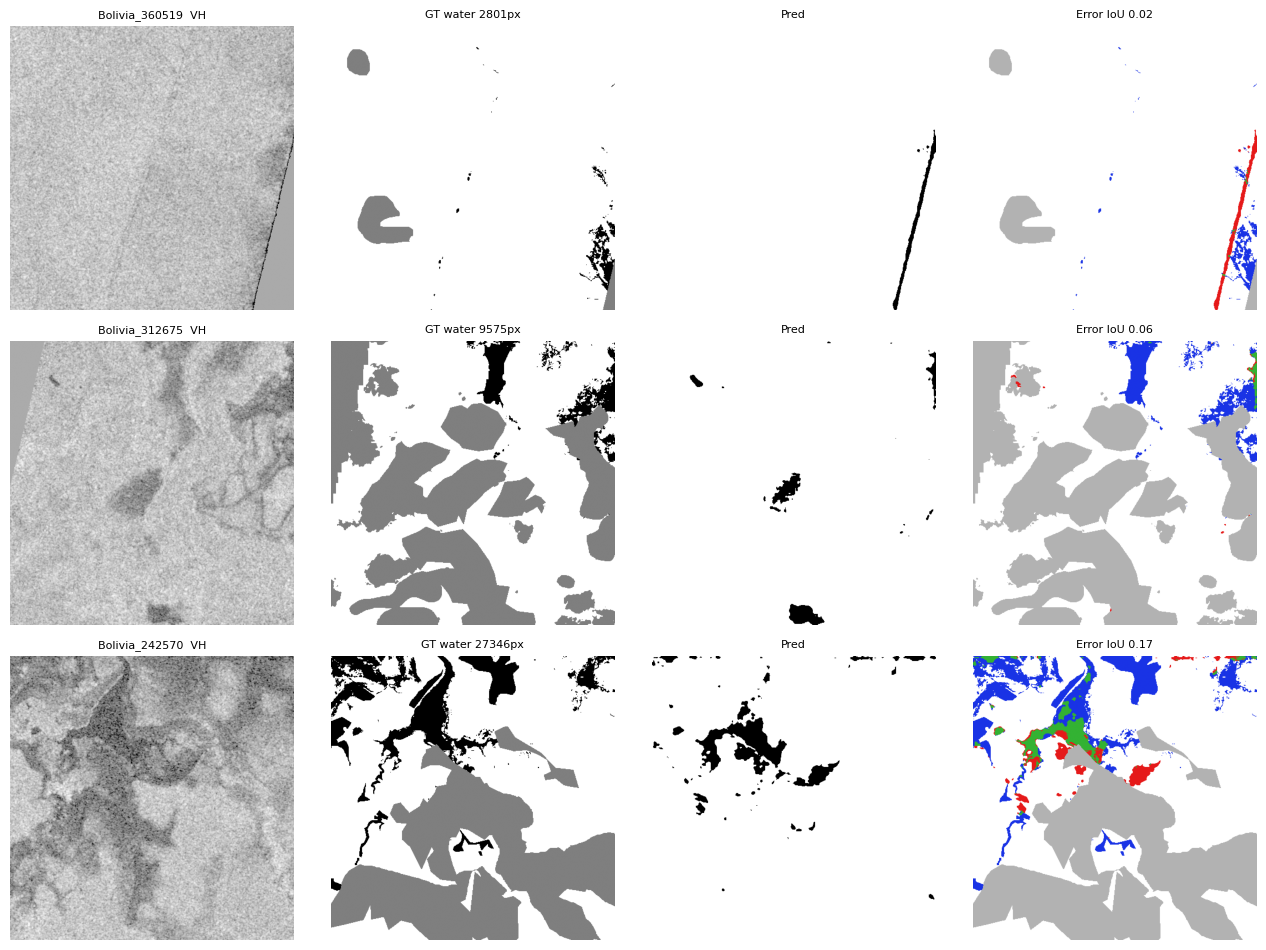

In [48]:
import matplotlib.pyplot as plt, os
os.makedirs(OUT, exist_ok=True)

model = smp.Unet("resnet34", encoder_weights=None, in_channels=2, classes=2).to(device)
model.load_state_dict(torch.load(f"{CKPT}/unet_vvvh.pt")); model.eval()

def per_chip(csv_name):
    ds, rows = FloodN(csv_name), []
    for i in range(len(ds)):
        x, y = ds[i]
        with torch.no_grad():
            p = model(x[None].to(device)).argmax(1)[0].cpu()
        tp = int(((p == 1) & (y == 1)).sum())
        fp = int(((p == 1) & (y == 0)).sum())
        fn = int(((p == 0) & (y == 1)).sum())
        iou = tp / (tp + fp + fn) if (tp + fp + fn) else float("nan")
        rows.append((ds.s1[i], iou, int((y == 1).sum()), p.numpy(), x.numpy(), y.numpy()))
    return rows

def show(rows, k, fname):
    rows = [r for r in rows if r[2] >= 2000 and r[1] == r[1]]
    rows = sorted(rows, key=lambda r: r[1])[:k]
    fig, ax = plt.subplots(k, 4, figsize=(13, 3.2 * k))
    ax = np.atleast_2d(ax)
    for r, a in zip(rows, ax):
        name, iou, water, p, x, y = r
        err = np.ones(y.shape + (3,))
        err[y == -1] = 0.7
        err[(p == 1) & (y == 1)] = [0.2, 0.7, 0.2]   # 맞게 찾은 물
        err[(p == 1) & (y == 0)] = [0.9, 0.1, 0.1]   # 잘못 물이라 한 곳
        err[(p == 0) & (y == 1)] = [0.1, 0.2, 0.9]   # 놓친 물
        a[0].imshow(x[1], cmap="gray"); a[0].set_title(f"{name[:-11]}  VH", fontsize=8)
        a[1].imshow(np.where(y == -1, 0.5, y), cmap="gray_r", vmin=0, vmax=1)
        a[1].set_title(f"GT water {water}px", fontsize=8)
        a[2].imshow(p, cmap="gray_r", vmin=0, vmax=1); a[2].set_title("Pred", fontsize=8)
        a[3].imshow(err); a[3].set_title(f"Error IoU {iou:.2f}", fontsize=8)
        for q in a: q.axis("off")
    plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=120); plt.show()

show(per_chip("flood_test_data.csv"), 4, "errors_test.png")
show(per_chip("flood_bolivia_data.csv"), 3, "errors_bolivia.png")

In [49]:
def nan_frac(csv_name):
    ds, out = Flood(csv_name), []
    for i in range(len(ds)):
        x, y = ds[i]
        out.append((ds.s1[i], float(torch.isnan(x).any(0).float().mean()), int((y == 1).sum())))
    return out

for n in ["test", "bolivia"]:
    bad = [(a, round(b, 2), c) for a, b, c in nan_frac(f"flood_{n}_data.csv") if b > 0.2]
    print(n, "NaN 20% 초과 칩:", len(bad))
    for t in bad: print("  ", t)

test NaN 20% 초과 칩: 4
   ('Nigeria_417184_S1Hand.tif', 0.4, 1384)
   ('Nigeria_22088_S1Hand.tif', 0.2, 629)
   ('Paraguay_34417_S1Hand.tif', 1.0, 50026)
   ('Sri-Lanka_450918_S1Hand.tif', 0.53, 4277)
bolivia NaN 20% 초과 칩: 3
   ('Bolivia_103757_S1Hand.tif', 0.61, 35362)
   ('Bolivia_23014_S1Hand.tif', 0.26, 7780)
   ('Bolivia_233925_S1Hand.tif', 0.25, 1)


In [50]:
EXCL = {"flood_test_data.csv": ["Paraguay_34417_S1Hand.tif", "Sri-Lanka_450918_S1Hand.tif"],
        "flood_bolivia_data.csv": ["Bolivia_103757_S1Hand.tif"]}

class Subset(torch.utils.data.Dataset):
    def __init__(self, csv_name, drop):
        self.ds = FloodN(csv_name)
        self.idx = [i for i, s in enumerate(self.ds.s1) if s not in drop]
    def __len__(self): return len(self.idx)
    def __getitem__(self, i): return self.ds[self.idx[i]]

rows = []
for tag in ["unet_vvvh", "unet_vvvh_s1", "unet_vvvh_s2"]:
    m = smp.Unet("resnet34", encoder_weights=None, in_channels=2, classes=2).to(device)
    m.load_state_dict(torch.load(f"{CKPT}/{tag}.pt")); m.eval()
    for csv in ["flood_test_data.csv", "flood_bolivia_data.csv"]:
        full = evaluate(m, DataLoader(FloodN(csv), batch_size=4))
        part = evaluate(m, DataLoader(Subset(csv, EXCL[csv]), batch_size=4))
        rows.append(dict(model=tag, split=csv[6:-9], IoU_all=round(full["IoU"], 3),
                         IoU_excl=round(part["IoU"], 3)))
cmp = pd.DataFrame(rows)
print(cmp.to_string(index=False))
print(cmp.groupby("split")[["IoU_all", "IoU_excl"]].agg(["mean", "min", "max"]).round(3))
cmp.to_csv(f"{OUT}/iou_with_without_nan_chips.csv", index=False)

       model   split  IoU_all  IoU_excl
   unet_vvvh    test    0.664     0.675
   unet_vvvh bolivia    0.674     0.661
unet_vvvh_s1    test    0.655     0.667
unet_vvvh_s1 bolivia    0.633     0.617
unet_vvvh_s2    test    0.665     0.677
unet_vvvh_s2 bolivia    0.627     0.613
        IoU_all               IoU_excl              
           mean    min    max     mean    min    max
split                                               
bolivia   0.645  0.627  0.674    0.630  0.613  0.661
test      0.661  0.655  0.665    0.673  0.667  0.677
